# M05 — CTA Ridership Exploratory Data Analysis

M04 ki cleaned bus aur rail CSVs ko tables aur charts se explore karein. Datasets separate hain: bus **route boardings** aur rail **station entries** measure karti hai, isliye unke numbers seedha ek jaisay compare na karein.

Ye 2022–2025 ke historical data ki analysis hai, live monitoring ya prediction nahi. Cells upar se neeche run karein.


## 1. Libraries aur cleaned files load karein

M04 pehle successfully run honi chahiye. Notebook project root, `backend` ya `backend/notebooks` se run ho sakti hai.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

if Path("backend/data/processed").is_dir():
    data_folder = Path("backend/data/processed")
elif Path("data/processed").is_dir():
    data_folder = Path("data/processed")
else:
    data_folder = Path("../data/processed")

bus = pd.read_csv(data_folder / "bus_cleaned.csv", dtype={"route": str}, parse_dates=["date"])
rail = pd.read_csv(data_folder / "rail_cleaned.csv", dtype={"station_id": str}, parse_dates=["date"])
datasets = {"Bus": bus, "Rail": rail}
print("Cleaned data folder:", data_folder.resolve())


Cleaned data folder: C:\UZZAM WORK\5th Semester\Artificial Intelligence & Expert Systems\Project\Transit_Ridership_M01_Setup\transit-ridership\backend\data\processed


## 2. Data overview

Rows, columns, date range aur sample rows dekhein. Har row bus ke liye **route-date**, aur rail ke liye **station-date** observation hai.


In [2]:
for name, df in datasets.items():
    print(f"\n{name}: {len(df):,} rows | {len(df.columns)} columns")
    print("Columns:", list(df.columns))
    print("Date range:", df["date"].min().date(), "to", df["date"].max().date())
    display(df.head())



Bus: 167,648 rows | 4 columns
Columns: ['route', 'date', 'daytype', 'rides']
Date range: 2022-01-01 to 2025-12-31


,route,date,daytype,rides
0,1,2022-01-03,W,385
1,1,2022-01-04,W,470
2,1,2022-01-05,W,289
3,1,2022-01-06,W,339
4,1,2022-01-07,W,233



Rail: 209,472 rows | 5 columns
Columns: ['station_id', 'stationname', 'date', 'daytype', 'rides']
Date range: 2022-01-01 to 2025-12-31


,station_id,stationname,date,daytype,rides
0,40010,Austin-Forest Park,2022-01-01,A,231
1,40020,Harlem-Lake,2022-01-01,A,500
2,40030,Pulaski-Lake,2022-01-01,A,284
3,40040,Quincy/Wells,2022-01-01,A,493
4,40050,Davis,2022-01-01,A,502


## 3. Ridership summary

Mean, median (50%) aur percentiles se rides ki distribution samajhte hain. Ye **per recorded route-day / station-day** statistics hain, total network ke daily passengers nahi.


In [3]:
for name, df in datasets.items():
    print(f"\n{name} — rides per recorded row")
    display(df["rides"].describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99]).to_frame("rides"))
    print("Zero-ride rows:", (df["rides"] == 0).sum())



Bus — rides per recorded row


,rides
count,167648.000000
mean,4044.225496
std,3839.691176
min,0.000000
25%,961.000000
50%,2757.000000
75%,6141.000000
90%,9620.000000
99%,16048.530000
max,23459.000000


Zero-ride rows: 2

Rail — rides per recorded row


,rides
count,209472.000000
mean,1970.937658
std,1938.233878
min,0.000000
25%,643.000000
50%,1346.000000
75%,2576.000000
90%,4470.000000
99%,9264.290000
max,26624.000000


Zero-ride rows: 2742


## 4. Monthly ridership trend

Har month mein recorded rides ka sum. Bus aur rail alag charts mein hain. Missing observations, route/station coverage ya service changes totals ko affect kar sakte hain; chart unka reason prove nahi karta.


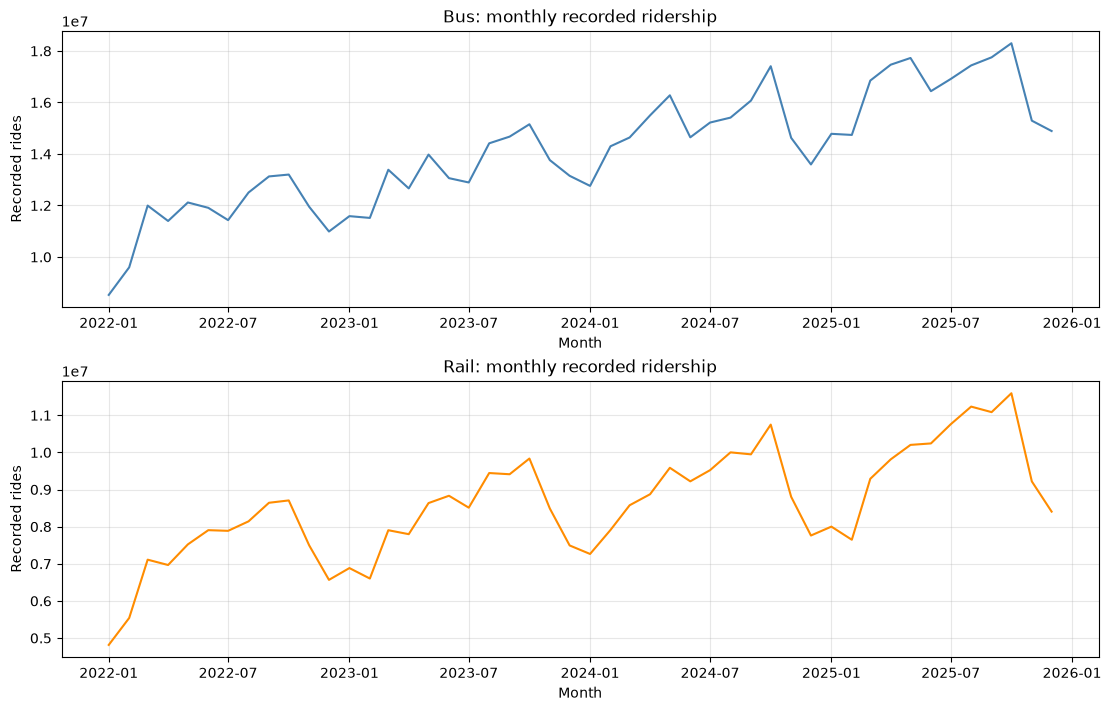

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(11, 7), constrained_layout=True)
for ax, (name, df) in zip(axes, datasets.items()):
    monthly = df.groupby(df["date"].dt.to_period("M"))["rides"].sum()
    monthly.index = monthly.index.to_timestamp()
    ax.plot(monthly.index, monthly.values, color="steelblue" if name == "Bus" else "darkorange")
    ax.set_title(f"{name}: monthly recorded ridership")
    ax.set_xlabel("Month")
    ax.set_ylabel("Recorded rides")
    ax.grid(alpha=0.3)
plt.show()


## 5. Day of week ka pattern

Har recorded row ki average rides, weekdays ke hisaab se. Ye per-route/per-station average hai; service frequency ya capacity ka direct measure nahi.


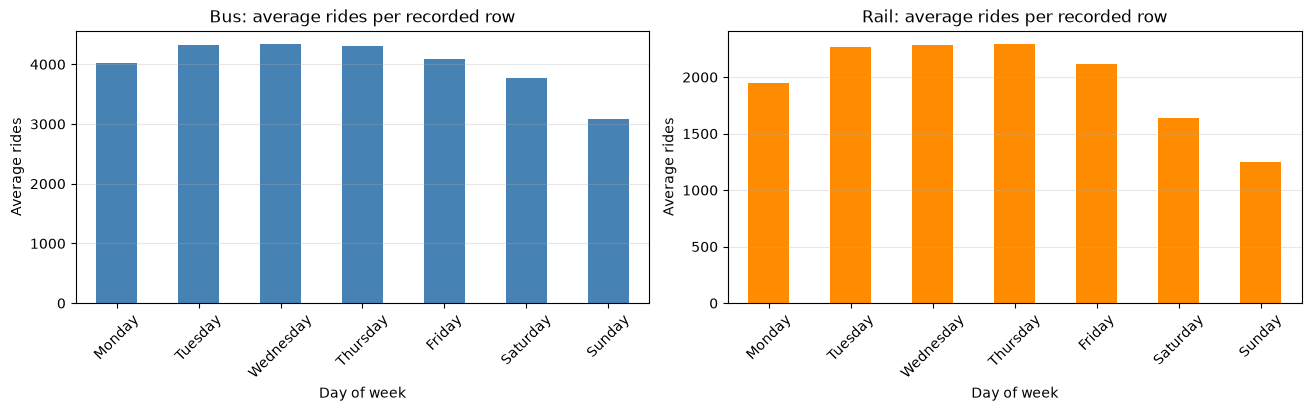

In [5]:
days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4), constrained_layout=True)
for ax, (name, df) in zip(axes, datasets.items()):
    daily_average = df.groupby(df["date"].dt.day_name())["rides"].mean().reindex(days)
    daily_average.plot.bar(ax=ax, color="steelblue" if name == "Bus" else "darkorange")
    ax.set_title(f"{name}: average rides per recorded row")
    ax.set_xlabel("Day of week")
    ax.set_ylabel("Average rides")
    ax.tick_params(axis="x", rotation=45)
    ax.grid(axis="y", alpha=0.3)
plt.show()


## 6. Ride distribution

Distribution ko readable rakhne ke liye sirf 99th percentile tak ki rows plot ki hain. **Highest 1% ke around observations chart se exclude hoti hain**; original data change nahi hota. Exact cutoff aur included/excluded counts print hote hain.


Bus: cutoff = 16,049, plotted = 165,971, excluded = 1,677
Rail: cutoff = 9,264, plotted = 207,377, excluded = 2,095


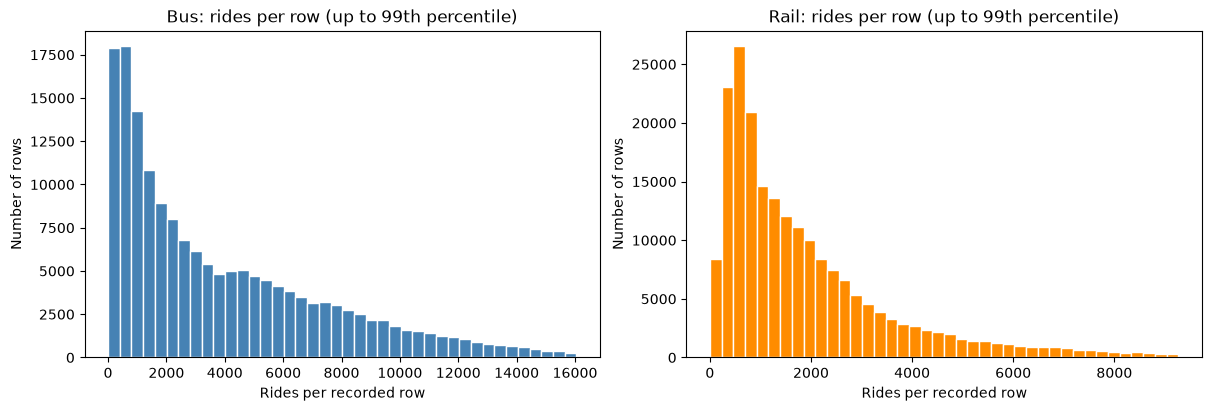

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for ax, (name, df) in zip(axes, datasets.items()):
    cutoff = df["rides"].quantile(0.99)
    shown = df.loc[df["rides"] <= cutoff, "rides"]
    print(f"{name}: cutoff = {cutoff:,.0f}, plotted = {len(shown):,}, excluded = {len(df) - len(shown):,}")
    ax.hist(shown, bins=40, color="steelblue" if name == "Bus" else "darkorange", edgecolor="white")
    ax.set_title(f"{name}: rides per row (up to 99th percentile)")
    ax.set_xlabel("Rides per recorded row")
    ax.set_ylabel("Number of rows")
plt.show()


## 7. High-average routes aur stations

Har entity ki available observations par mean calculate hota hai. `recorded_days` bhi dikhaye gaye hain, kyunki kam observations wali entity ki average kam representative ho sakti hai. Ye rankings capacity, overcrowding ya future demand nahi batatin.


In [7]:
for name, df in datasets.items():
    entity = "route" if name == "Bus" else "station_id"
    ranking = df.groupby(entity)["rides"].agg(average_rides="mean", recorded_days="count")
    ranking = ranking.sort_values("average_rides", ascending=False).head(10)
    ranking["average_rides"] = ranking["average_rides"].round(1)
    print(f"\n{name} — top 10 by average rides per recorded day")
    display(ranking)



Bus — top 10 by average rides per recorded day


,average_rides,recorded_days
route,,
66,13909.6,1461
9,13107.2,1461
79,13041.6,1461
8,12278.8,1461
53,11765.8,1461
77,11209.4,1461
22,10929.8,1461
49,10782.1,1461
3,10736.6,1461



Rail — top 10 by average rides per recorded day


,average_rides,recorded_days
station_id,,
41660,8793.9,1461
40890,7935.1,1461
40380,7339.5,1461
41450,6552.3,1461
40260,6521.5,1461
41220,6465.6,1461
41400,6182.3,1461
41320,6106.2,1461
40370,5972.2,1461


## 8. Apni observations likhein

- Monthly trend aur weekday pattern mein tumhein kya nazar aaya?
- Mean aur median mein kitna difference hai? High values ka kya effect ho sakta hai?
- Entity rankings interpret karte waqt `recorded_days` kyun dekhna chahiye?

**Limitations:** Ye descriptive analysis full available period par hai. Isay future ML evaluation ka result na samjhein. Model ke liye chronological split aur training data se fitted transformations alag plan honge.
